In [4]:
ENV["MPLBACKEND"] = "agg"
using QuantumOptics
using PyPlot
using IonSim

In [5]:
function plot_wigner(final_state)
    rho_motional = ptrace(final_state, 1)

b_fock = FockBasis(50)
rho_fock = DenseOperator(b_fock, rho_motional.data)

x_vec = -4.0:0.1:4.0
p_vec = -4.0:0.1:4.0

W = wigner(rho_fock, x_vec, p_vec)

fig = figure(figsize=(8, 6))
PyPlot.pcolormesh(x_vec, p_vec, W, cmap="RdBu_r", vmin=-0.2, vmax=0.2, shading="nearest")
PyPlot.colorbar(label="Wigner Function W(x, p)")

# Add a marker where the vacuum state (0,0) originally was
PyPlot.plot([0], [0], "w+", markersize=15, markeredgewidth=2, label="Original Vacuum |0>")

PyPlot.xlabel("Position (x)")
PyPlot.ylabel("Momentum (p)")
PyPlot.title("Displaced Motional State")
PyPlot.legend()
PyPlot.grid(color="white", alpha=0.2)

# Display the figure safely in Jupyter (removed show() to prevent the device warning)
display(fig)
end

plot_wigner (generic function with 1 method)

In [ ]:
ENV["MPLBACKEND"] = "agg"
using IonSim
using QuantumOptics
using PyPlot
using LinearAlgebra

function laguerre(n::Int, x::Float64)
    if n == 0 return 1.0 end
    if n == 1 return 1.0 - x end
    L_prev2 = 1.0
    L_prev1 = 1.0 - x
    L_curr = 0.0
    for k in 1:(n-1)
        L_curr = ((2k + 1 - x) * L_prev1 - k * L_prev2) / (k + 1)
        L_prev2 = L_prev1
        L_prev1 = L_curr
    end
    return L_curr
end

function calculate_qcrb(state, state_perturbed, d_alpha::Float64; tol=1e-10)
    rho1 = isa(state, Ket) ? dm(state) : state
    rho2 = isa(state_perturbed, Ket) ? dm(state_perturbed) : state_perturbed
    
    rho_dense_data = dense(rho1).data
    rho_pert_dense_data = dense(rho2).data

    drho_data = (rho_pert_dense_data - rho_dense_data) / d_alpha
    λ, V = LinearAlgebra.eigen(Hermitian(rho_dense_data))
    
    qfi = 0.0
    n = length(λ)
    for i in 1:n
        for j in 1:n
            if real(λ[i] + λ[j]) > tol
                @views v_i = V[:, i]
                @views v_j = V[:, j]
                drho_ij = dot(v_i, drho_data * v_j)
                qfi += 2 * (abs(drho_ij)^2) / real(λ[i] + λ[j])
            end
        end
    end
    
    qcrb = qfi > 0 ? 1.0 / qfi : Inf
    return qfi, qcrb
end

function SDF_apply_with_alpha_dephasing(laser_intensity = 1e4, angle = 0.0, target_disp = 0.716, is_SDF = false, initial_state = nothing, fock_state_n = 0, gamma_phi_set = 1e-2, baseline_beta = 1.0)
    trap_freq = 19e5 
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
    
    mode_z = zmodes(chain)[1] 
    mode_z.N = 50
    mode_z.shape = [51]
    
    k_vec = (x̂ + ẑ) / √2
    ϵ_vec = ŷ
    B_field = 1e-13
    
    trap_pre = Chamber(iontrap=chain, B=B_field, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    mode = zmodes(trap_pre)[1]
    
    ψ_ion = normalize(ion["g"])
    ψ_mode = fockstate(mode, fock_state_n)
    ψ_initial = initial_state !== nothing ? initial_state : (ψ_ion ⊗ ψ_mode)

    hbar = 1.0545718e-34       
    amu = 1.66053906e-27       
    m_Ca40 = 39.96259 * amu    
    
    omega_trap = 2 * π * trap_freq
    z_zpf = sqrt(hbar / (2 * m_Ca40 * omega_trap))
    k_total = 2 * π / transition_λ
    k_z = k_total / sqrt(2)
    eta = k_z * z_zpf

    dummy_laser = Laser(I=laser_intensity, k=k_vec, ϵ=ϵ_vec, λ=transition_λ)
    Bhat_tuple = (; x=0.0, y=0.0, z=1.0)
    
    Omega_eff_Hz = IonSim.matrixelement(ion, ("g", "e"), laser_intensity, polarization(dummy_laser), wavevector(dummy_laser), Bhat_tuple)
    Omega_eff = Omega_eff_Hz * 2 * π

    if is_SDF
        alpha_complex = target_disp * exp(1im * angle)
        g = ion["g"]
        e = ion["e"]
        
        x_plus = normalize(g + e)
        x_minus = normalize(g - e)
        
        P_plus = x_plus ⊗ dagger(x_plus)
        P_minus = x_minus ⊗ dagger(x_minus)
        
        D_plus = IonSim.displace(mode, alpha_complex)
        D_minus = IonSim.displace(mode, -alpha_complex)
        
        U_SDF = (P_plus ⊗ D_plus) + (P_minus ⊗ D_minus)
        
        if isa(ψ_initial, Operator)
            return U_SDF * ψ_initial * dagger(U_SDF)
        else
            return U_SDF * ψ_initial
        end
    else
        I_spin = identityoperator(ion["g"].basis)  
        gamma_phi_us = gamma_phi_set * 1e-6 

        temp_fock_basis = FockBasis(mode.N) 
        a_op = DenseOperator(mode, mode, QuantumOptics.destroy(temp_fock_basis).data)
        at_op = DenseOperator(mode, mode, QuantumOptics.create(temp_fock_basis).data)
        n_op = DenseOperator(mode, mode, QuantumOptics.number(temp_fock_basis).data)

        # Time is locked to the macroscopic baseline target
        target_time_s = (2 * baseline_beta) / (eta * Omega_eff)
        target_time_us = target_time_s * 1e6

        # Drive amplitude scales with the actual requested target_disp
        drive_rate = target_disp / target_time_us
        H_m = (1im * drive_rate) * (exp(1im * angle) * at_op - exp(-1im * angle) * a_op)
        H_sys = I_spin ⊗ H_m

        n_sys = I_spin ⊗ n_op
        J_dephase = sqrt(gamma_phi_us) * n_sys
        J_ops = [J_dephase]
        J_ops_dag = dagger.(J_ops)

        function f_dyn(time_t, rho_state)
            return (H_sys, J_ops, J_ops_dag)
        end

        rho_initial = isa(ψ_initial, Ket) ? dm(ψ_initial) : ψ_initial
        tspan_sdf = [0.0, target_time_us]

        _, sol_beta = timeevolution.master_dynamic(tspan_sdf, rho_initial, f_dyn, reltol=1e-9, abstol=1e-11)

        return sol_beta[end]
    end
end

function get_qcrb_coordinates_macroscopic_beta(n_fock::Int=3, laser_intensity::Float64=1e3, gamma_phi::Float64=250.0, beta_signal::Float64=1.0)
    d_beta = 1e-4 
    
    trap_freq = 19e5 
    hbar = 1.0545718e-34       
    amu = 1.66053906e-27       
    m_Ca40 = 39.96259 * amu    
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
    trap_pre = Chamber(iontrap=chain, B=1e-13, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    sim_mode = zmodes(trap_pre)[1]
    sim_mode.N = 50
    sim_mode.shape = [51]

    N_cut = 50
    b_fock = FockBasis(N_cut) 
    psi_init_qo = fockstate(b_fock, n_fock)
    spin_g = normalize(ion["g"])

    initial_sys_origin = spin_g ⊗ Ket(sim_mode, psi_init_qo.data)

    println("\nRunning master_dynamic (Drifting to macroscopic β=$(beta_signal) in the bath)...")
    
    # Wavepacket drives to baseline beta and beta + perturbation in the dephasing bath
    noisy_beta_state = SDF_apply_with_alpha_dephasing(laser_intensity, 0.0, beta_signal, false, initial_sys_origin, n_fock, gamma_phi, beta_signal)
    noisy_beta_state_pert = SDF_apply_with_alpha_dephasing(laser_intensity, 0.0, beta_signal + d_beta, false, initial_sys_origin, n_fock, gamma_phi, beta_signal)

    alphas = collect(0.1:0.05:1.6)
    sim_qcrbs = Float64[]
    theory_closed_qcrbs = Float64[]

    println("Sweeping α (Applying instantaneous SDF Split)...")
    for a in alphas
        state_a_full = SDF_apply_with_alpha_dephasing(laser_intensity, pi/2, a, true, noisy_beta_state, n_fock, gamma_phi, beta_signal)
        state_a_pert_full = SDF_apply_with_alpha_dephasing(laser_intensity, pi/2, a, true, noisy_beta_state_pert, n_fock, gamma_phi, beta_signal)

        rho_spin_a = ptrace(state_a_full, 2)
        rho_spin_a_pert = ptrace(state_a_pert_full, 2)
        
        _, qcrb_sim = calculate_qcrb(rho_spin_a, rho_spin_a_pert, d_beta)
        push!(sim_qcrbs, qcrb_sim)

        L_val = laguerre(n_fock, 4 * a^2)
        qcrb_closed = exp(4 * a^2) / (16 * a^2 * L_val^2)
        push!(theory_closed_qcrbs, qcrb_closed)
    end

    return alphas, sim_qcrbs, theory_closed_qcrbs
end

function plot_qcrb_macroscopic_beta(n_fock::Int=3, laser_intensity::Float64=1e3, gamma_phi::Float64=250.0, beta_signal::Float64=1.0)
    x_alpha, y_sim, y_closed = get_qcrb_coordinates_macroscopic_beta(n_fock, laser_intensity, gamma_phi, beta_signal)

    fig = figure(figsize=(9, 6))
    
    plot(x_alpha, y_sim, "o-", markersize=7, color="dodgerblue", linewidth=2.5, label="Simulation (Macroscopic β=$(beta_signal) Drift)")
    plot(x_alpha, y_closed, "r:", linewidth=2.0, label="Theory (Ideal Closed System)")

    yscale("log")
    ylim(1e-1, 2e3)
    xlabel("Readout Displacement [α]", fontsize=12)
    ylabel("QCRB (Ancilla Measurement Limit)", fontsize=12)
    title("Dephasing at Macroscopic β=$(beta_signal): Fock = $(n_fock), Γ_ϕ = $(gamma_phi) Hz", fontsize=11)
    
    legend(fontsize=10, loc="upper left")
    grid(alpha=0.4)
    
    display(fig)
end

# Example test run for the modified beta=2.0 parameter
plot_qcrb_macroscopic_beta(1, 1e3, 365.0, 2.0)

SDF_apply_with_alpha_dephasing (generic function with 8 methods)

In [12]:
beta = SDF_apply_with_alpha_dephasing(1e4, 0, 0.716, false, nothing, 0, 1e2)

Operator(dim=102x102)
  basis: [⁴⁰Ca ⊗ VibrationalMode(ν=1.9e6, axis=ẑ, N=50)]
  0.602461+0.0im  0.0+0.0im  …  0.0+0.0im  0.0+0.0im  0.0+0.0im
       0.0+0.0im  0.0+0.0im     0.0+0.0im  0.0+0.0im  0.0+0.0im
  0.423889+0.0im  0.0+0.0im     0.0+0.0im  0.0+0.0im  0.0+0.0im
       0.0+0.0im  0.0+0.0im     0.0+0.0im  0.0+0.0im  0.0+0.0im
  0.206091+0.0im  0.0+0.0im     0.0+0.0im  0.0+0.0im  0.0+0.0im
       0.0+0.0im  0.0+0.0im  …  0.0+0.0im  0.0+0.0im  0.0+0.0im
 0.0799759+0.0im  0.0+0.0im     0.0+0.0im  0.0+0.0im  0.0+0.0im
       0.0+0.0im  0.0+0.0im     0.0+0.0im  0.0+0.0im  0.0+0.0im
 0.0262824+0.0im  0.0+0.0im     0.0+0.0im  0.0+0.0im  0.0+0.0im
       0.0+0.0im  0.0+0.0im     0.0+0.0im  0.0+0.0im  0.0+0.0im
          ⋮                  ⋱                ⋮       
       0.0+0.0im  0.0+0.0im     0.0+0.0im  0.0+0.0im  0.0+0.0im
       0.0+0.0im  0.0+0.0im     0.0+0.0im  0.0+0.0im  0.0+0.0im
       0.0+0.0im  0.0+0.0im  …  0.0+0.0im  0.0+0.0im  0.0+0.0im
       0.0+0.0im  0.0+0.0im     0

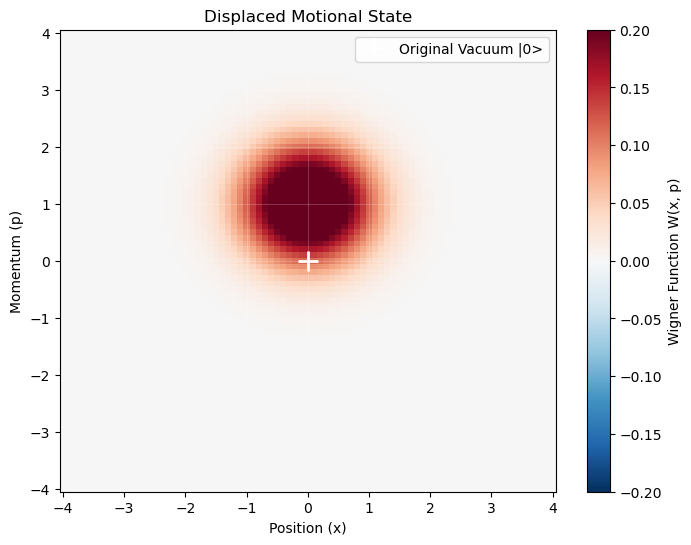

In [13]:
plot_wigner(beta)

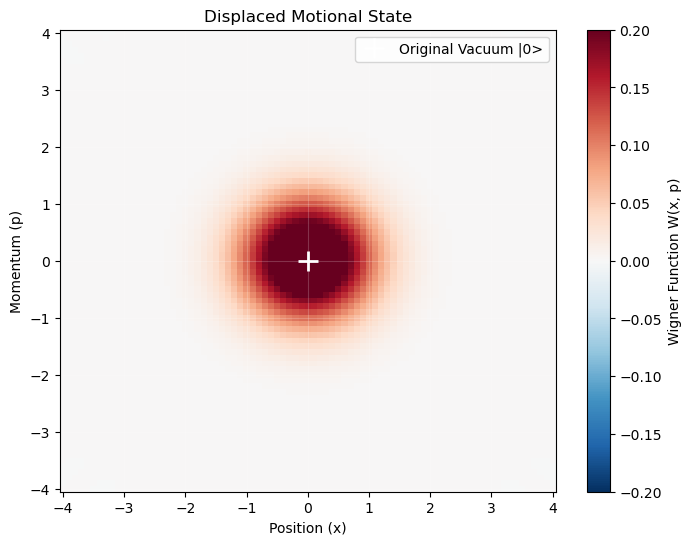

In [15]:
beta = SDF_apply_with_alpha_dephasing(1e4, 0, 0.716, false, nothing, 0, 1e5)
plot_wigner(beta)

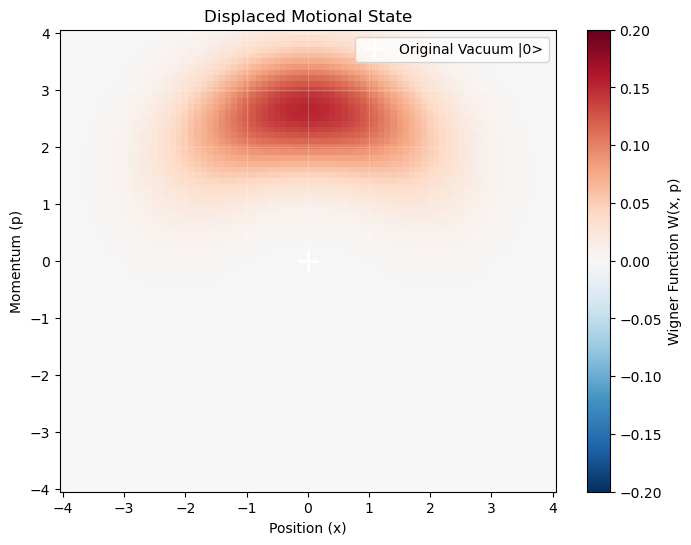

In [16]:
beta = SDF_apply_with_alpha_dephasing(1e4, 0, 2.0, false, nothing, 0, 1e3)
plot_wigner(beta)

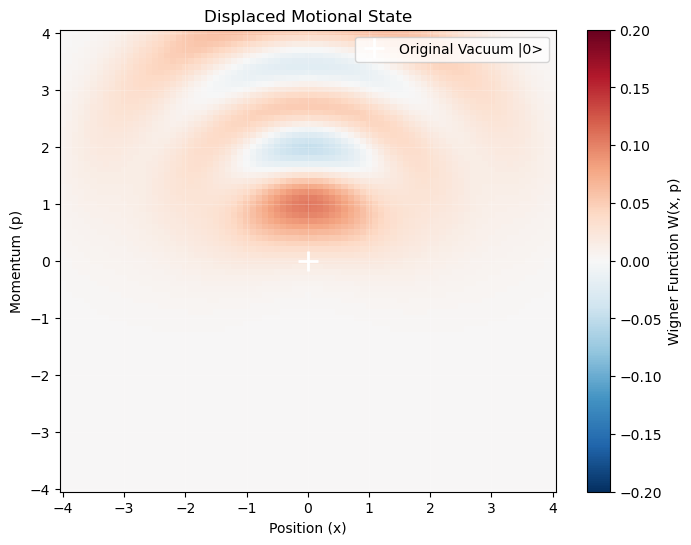

In [17]:
beta = SDF_apply_with_alpha_dephasing(1e4, 0, 2.0, false, nothing, 2, 1e3)
plot_wigner(beta)

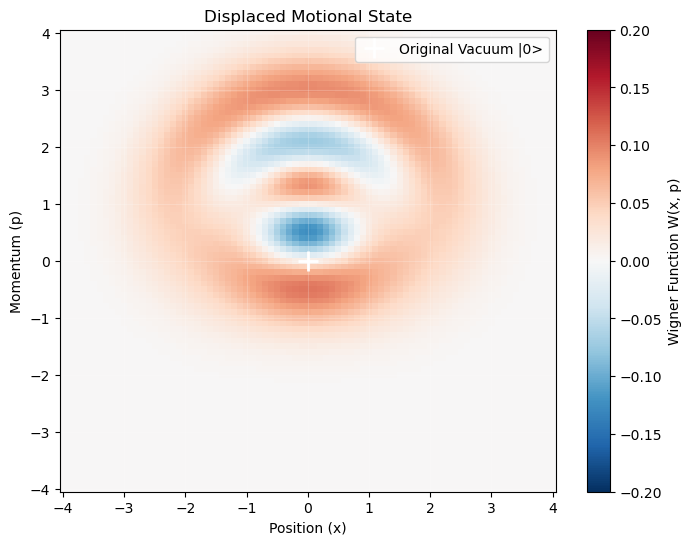

In [18]:
beta = SDF_apply_with_alpha_dephasing(1e4, 0, 1.0, false, nothing, 2, 1e3)
plot_wigner(beta)

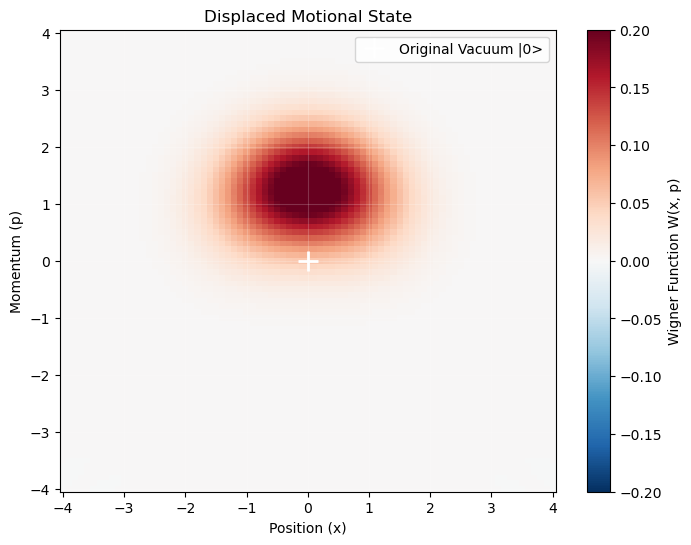

In [19]:
beta = SDF_apply_with_alpha_dephasing(1e4, 0, 1.0, false, nothing, 0, 1e3)
plot_wigner(beta)

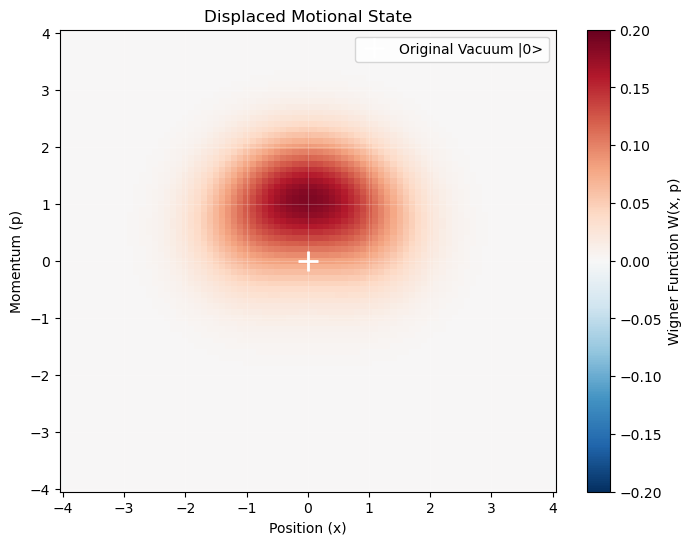

In [21]:
beta = SDF_apply_with_alpha_dephasing(1e3, 0, 1.0, false, nothing, 0, 1e3)
plot_wigner(beta)

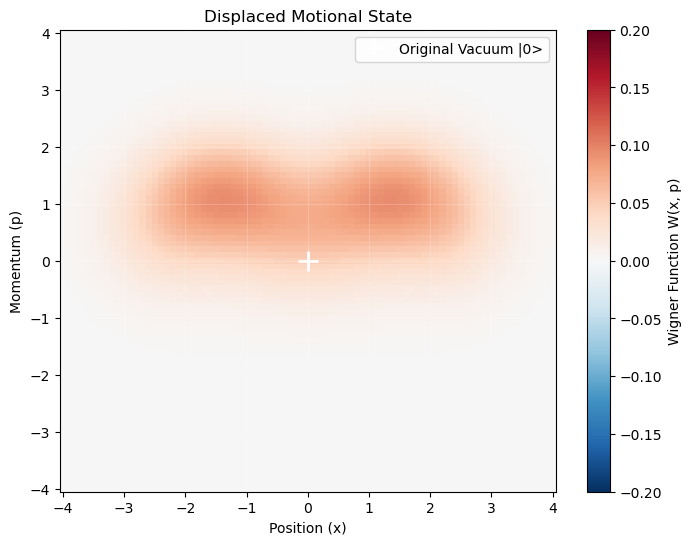

In [35]:
alpha = SDF_apply_with_alpha_dephasing(1e3, pi/2, 1.0, true, beta, 0, 1e3, 1.0)
plot_wigner(alpha)


Running master_dynamic (Drifting to macroscopic β=2.0 in the bath)...
Sweeping α (Applying instantaneous SDF Split)...


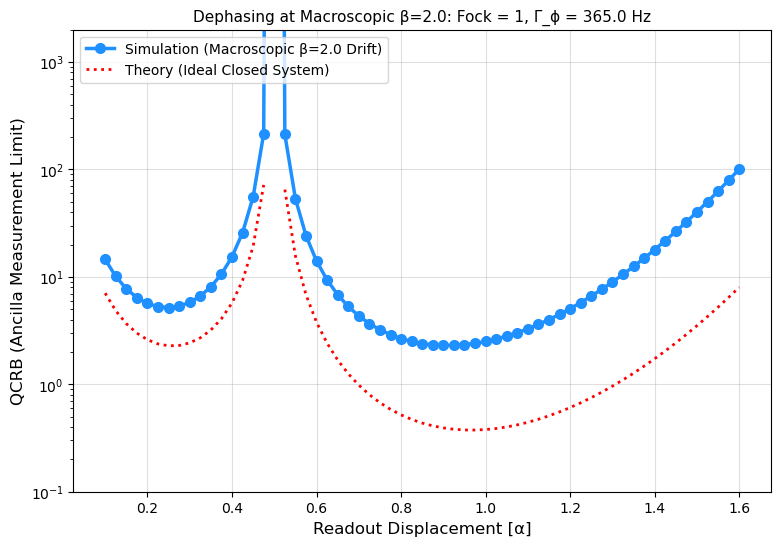

In [25]:
ENV["MPLBACKEND"] = "agg"
using IonSim
using QuantumOptics
using PyPlot
using LinearAlgebra

function laguerre(n::Int, x::Float64)
    if n == 0 return 1.0 end
    if n == 1 return 1.0 - x end
    L_prev2 = 1.0
    L_prev1 = 1.0 - x
    L_curr = 0.0
    for k in 1:(n-1)
        L_curr = ((2k + 1 - x) * L_prev1 - k * L_prev2) / (k + 1)
        L_prev2 = L_prev1
        L_prev1 = L_curr
    end
    return L_curr
end

function calculate_qcrb(state, state_perturbed, d_alpha::Float64; tol=1e-10)
    rho1 = isa(state, Ket) ? dm(state) : state
    rho2 = isa(state_perturbed, Ket) ? dm(state_perturbed) : state_perturbed
    
    rho_dense_data = dense(rho1).data
    rho_pert_dense_data = dense(rho2).data

    drho_data = (rho_pert_dense_data - rho_dense_data) / d_alpha
    λ, V = LinearAlgebra.eigen(Hermitian(rho_dense_data))
    
    qfi = 0.0
    n = length(λ)
    for i in 1:n
        for j in 1:n
            if real(λ[i] + λ[j]) > tol
                @views v_i = V[:, i]
                @views v_j = V[:, j]
                drho_ij = dot(v_i, drho_data * v_j)
                qfi += 2 * (abs(drho_ij)^2) / real(λ[i] + λ[j])
            end
        end
    end
    
    qcrb = qfi > 0 ? 1.0 / qfi : Inf
    return qfi, qcrb
end

function SDF_apply_with_alpha_dephasing(laser_intensity = 1e4, angle = 0.0, target_disp = 0.716, is_SDF = false, initial_state = nothing, fock_state_n = 0, gamma_phi_set = 1e-2, baseline_beta = 1.0)
    trap_freq = 19e5 
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
    
    mode_z = zmodes(chain)[1] 
    mode_z.N = 50
    mode_z.shape = [51]
    
    k_vec = (x̂ + ẑ) / √2
    ϵ_vec = ŷ
    B_field = 1e-13
    
    trap_pre = Chamber(iontrap=chain, B=B_field, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    mode = zmodes(trap_pre)[1]
    
    ψ_ion = normalize(ion["g"])
    ψ_mode = fockstate(mode, fock_state_n)
    ψ_initial = initial_state !== nothing ? initial_state : (ψ_ion ⊗ ψ_mode)

    hbar = 1.0545718e-34       
    amu = 1.66053906e-27       
    m_Ca40 = 39.96259 * amu    
    
    omega_trap = 2 * π * trap_freq
    z_zpf = sqrt(hbar / (2 * m_Ca40 * omega_trap))
    k_total = 2 * π / transition_λ
    k_z = k_total / sqrt(2)
    eta = k_z * z_zpf

    dummy_laser = Laser(I=laser_intensity, k=k_vec, ϵ=ϵ_vec, λ=transition_λ)
    Bhat_tuple = (; x=0.0, y=0.0, z=1.0)
    
    Omega_eff_Hz = IonSim.matrixelement(ion, ("g", "e"), laser_intensity, polarization(dummy_laser), wavevector(dummy_laser), Bhat_tuple)
    Omega_eff = Omega_eff_Hz * 2 * π

    if is_SDF
        alpha_complex = target_disp * exp(1im * angle)
        g = ion["g"]
        e = ion["e"]
        
        x_plus = normalize(g + e)
        x_minus = normalize(g - e)
        
        P_plus = x_plus ⊗ dagger(x_plus)
        P_minus = x_minus ⊗ dagger(x_minus)
        
        D_plus = IonSim.displace(mode, alpha_complex)
        D_minus = IonSim.displace(mode, -alpha_complex)
        
        U_SDF = (P_plus ⊗ D_plus) + (P_minus ⊗ D_minus)
        
        if isa(ψ_initial, Operator)
            return U_SDF * ψ_initial * dagger(U_SDF)
        else
            return U_SDF * ψ_initial
        end
    else
        I_spin = identityoperator(ion["g"].basis)  
        gamma_phi_us = gamma_phi_set * 1e-6 

        temp_fock_basis = FockBasis(mode.N) 
        a_op = DenseOperator(mode, mode, QuantumOptics.destroy(temp_fock_basis).data)
        at_op = DenseOperator(mode, mode, QuantumOptics.create(temp_fock_basis).data)
        n_op = DenseOperator(mode, mode, QuantumOptics.number(temp_fock_basis).data)

        # Time is locked to the macroscopic baseline target
        target_time_s = (2 * baseline_beta) / (eta * Omega_eff)
        target_time_us = target_time_s * 1e6

        # Drive amplitude scales with the actual requested target_disp
        drive_rate = target_disp / target_time_us
        H_m = (1im * drive_rate) * (exp(1im * angle) * at_op - exp(-1im * angle) * a_op)
        H_sys = I_spin ⊗ H_m

        n_sys = I_spin ⊗ n_op
        J_dephase = sqrt(gamma_phi_us) * n_sys
        J_ops = [J_dephase]
        J_ops_dag = dagger.(J_ops)

        function f_dyn(time_t, rho_state)
            return (H_sys, J_ops, J_ops_dag)
        end

        rho_initial = isa(ψ_initial, Ket) ? dm(ψ_initial) : ψ_initial
        tspan_sdf = [0.0, target_time_us]

        _, sol_beta = timeevolution.master_dynamic(tspan_sdf, rho_initial, f_dyn, reltol=1e-9, abstol=1e-11)

        return sol_beta[end]
    end
end

function get_qcrb_coordinates_macroscopic_beta(n_fock::Int=3, laser_intensity::Float64=1e3, gamma_phi::Float64=250.0, beta_signal::Float64=1.0)
    d_beta = 1e-4 
    
    trap_freq = 19e5 
    hbar = 1.0545718e-34       
    amu = 1.66053906e-27       
    m_Ca40 = 39.96259 * amu    
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
    trap_pre = Chamber(iontrap=chain, B=1e-13, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    sim_mode = zmodes(trap_pre)[1]
    sim_mode.N = 50
    sim_mode.shape = [51]

    N_cut = 50
    b_fock = FockBasis(N_cut) 
    psi_init_qo = fockstate(b_fock, n_fock)
    spin_g = normalize(ion["g"])

    initial_sys_origin = spin_g ⊗ Ket(sim_mode, psi_init_qo.data)

    println("\nRunning master_dynamic (Drifting to macroscopic β=$(beta_signal) in the bath)...")
    
    # Wavepacket drives to baseline beta and beta + perturbation in the dephasing bath
    noisy_beta_state = SDF_apply_with_alpha_dephasing(laser_intensity, 0.0, beta_signal, false, initial_sys_origin, n_fock, gamma_phi, beta_signal)
    noisy_beta_state_pert = SDF_apply_with_alpha_dephasing(laser_intensity, 0.0, beta_signal + d_beta, false, initial_sys_origin, n_fock, gamma_phi, beta_signal)

    alphas = collect(0.1:0.025:1.6)
    sim_qcrbs = Float64[]
    theory_closed_qcrbs = Float64[]

    println("Sweeping α (Applying instantaneous SDF Split)...")
    for a in alphas
        state_a_full = SDF_apply_with_alpha_dephasing(laser_intensity, pi/2, a, true, noisy_beta_state, n_fock, gamma_phi, beta_signal)
        state_a_pert_full = SDF_apply_with_alpha_dephasing(laser_intensity, pi/2, a, true, noisy_beta_state_pert, n_fock, gamma_phi, beta_signal)

        rho_spin_a = ptrace(state_a_full, 2)
        rho_spin_a_pert = ptrace(state_a_pert_full, 2)
        
        _, qcrb_sim = calculate_qcrb(rho_spin_a, rho_spin_a_pert, d_beta)
        push!(sim_qcrbs, qcrb_sim)

        L_val = laguerre(n_fock, 4 * a^2)
        qcrb_closed = exp(4 * a^2) / (16 * a^2 * L_val^2)
        push!(theory_closed_qcrbs, qcrb_closed)
    end

    return alphas, sim_qcrbs, theory_closed_qcrbs
end

function plot_qcrb_macroscopic_beta(n_fock::Int=3, laser_intensity::Float64=1e3, gamma_phi::Float64=250.0, beta_signal::Float64=1.0)
    x_alpha, y_sim, y_closed = get_qcrb_coordinates_macroscopic_beta(n_fock, laser_intensity, gamma_phi, beta_signal)

    fig = figure(figsize=(9, 6))
    
    plot(x_alpha, y_sim, "o-", markersize=7, color="dodgerblue", linewidth=2.5, label="Simulation (Macroscopic β=$(beta_signal) Drift)")
    plot(x_alpha, y_closed, "r:", linewidth=2.0, label="Theory (Ideal Closed System)")

    yscale("log")
    ylim(1e-1, 2e3)
    xlabel("Readout Displacement [α]", fontsize=12)
    ylabel("QCRB (Ancilla Measurement Limit)", fontsize=12)
    title("Dephasing at Macroscopic β=$(beta_signal): Fock = $(n_fock), Γ_ϕ = $(gamma_phi) Hz", fontsize=11)
    
    legend(fontsize=10, loc="upper left")
    grid(alpha=0.4)
    
    display(fig)
end

# Example test run for the modified beta=2.0 parameter
plot_qcrb_macroscopic_beta(1, 1e3, 365.0, 2.0)

Gamma_t = 1.6108723765003177, t_sig_s = 0.004413348976713199 s, eta = 0.04971125874691094, Omega_eff = 18232.111218474965 rad/s

Running master_dynamic (Drifting to macroscopic β=2.0 in the bath)...
Running Stepwise Analytical Open Theory (Trotter Expansion)...
Sweeping α (Evaluating Simulation, Exact Open Theory, and Closed Theory)...


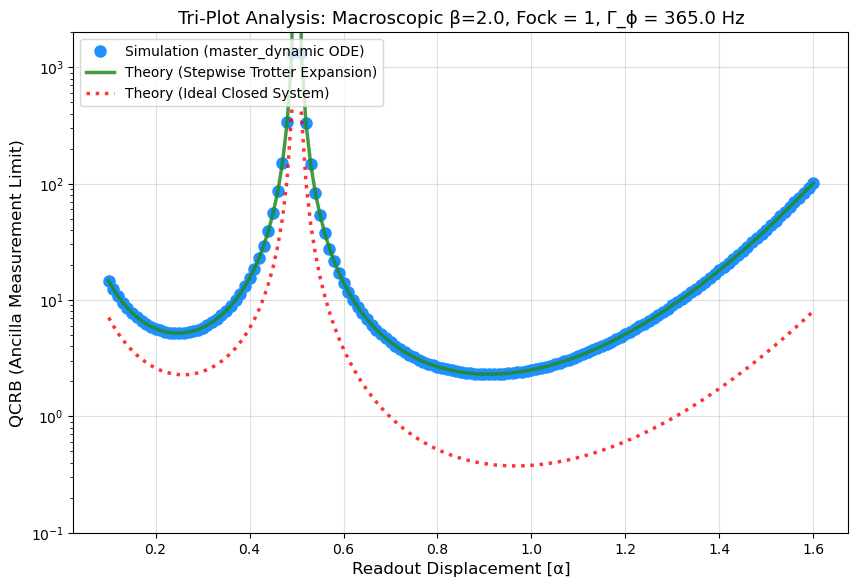

In [32]:
ENV["MPLBACKEND"] = "agg"
using IonSim
using QuantumOptics
using PyPlot
using LinearAlgebra

# -------------------------------------------------------------
# Math Helpers
# -------------------------------------------------------------
function laguerre(n::Int, x::Float64)
    if n == 0 return 1.0 end
    if n == 1 return 1.0 - x end
    L_prev2 = 1.0
    L_prev1 = 1.0 - x
    L_curr = 0.0
    for k in 1:(n-1)
        L_curr = ((2k + 1 - x) * L_prev1 - k * L_prev2) / (k + 1)
        L_prev2 = L_prev1
        L_prev1 = L_curr
    end
    return L_curr
end

function calculate_qcrb(state, state_perturbed, d_alpha::Float64; tol=1e-10)
    rho1 = isa(state, Ket) ? dm(state) : state
    rho2 = isa(state_perturbed, Ket) ? dm(state_perturbed) : state_perturbed
    rho_dense_data = dense(rho1).data
    rho_pert_dense_data = dense(rho2).data
    drho_data = (rho_pert_dense_data - rho_dense_data) / d_alpha
    λ, V = LinearAlgebra.eigen(Hermitian(rho_dense_data))
    
    qfi = 0.0
    n = length(λ)
    for i in 1:n
        for j in 1:n
            if real(λ[i] + λ[j]) > tol
                @views v_i = V[:, i]
                @views v_j = V[:, j]
                drho_ij = dot(v_i, drho_data * v_j)
                qfi += 2 * (abs(drho_ij)^2) / real(λ[i] + λ[j])
            end
        end
    end
    
    qcrb = qfi > 0 ? 1.0 / qfi : Inf
    return qfi, qcrb
end

# -------------------------------------------------------------
# Simulation ODE Logic
# -------------------------------------------------------------
function SDF_apply_with_alpha_dephasing(laser_intensity = 1e4, angle = 0.0, target_disp = 0.716, is_SDF = false, initial_state = nothing, fock_state_n = 0, gamma_phi_set = 1e-2, baseline_beta = 1.0)
    trap_freq = 19e5 
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
    mode_z = zmodes(chain)[1] 
    mode_z.N = 50
    mode_z.shape = [51]
    
    k_vec = (x̂ + ẑ) / √2
    ϵ_vec = ŷ
    B_field = 1e-13
    
    trap_pre = Chamber(iontrap=chain, B=B_field, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    mode = zmodes(trap_pre)[1]
    
    ψ_ion = normalize(ion["g"])
    ψ_mode = fockstate(mode, fock_state_n)
    ψ_initial = initial_state !== nothing ? initial_state : (ψ_ion ⊗ ψ_mode)

    hbar = 1.0545718e-34       
    amu = 1.66053906e-27       
    m_Ca40 = 39.96259 * amu    
    
    omega_trap = 2 * π * trap_freq
    z_zpf = sqrt(hbar / (2 * m_Ca40 * omega_trap))
    k_z = (2 * π / transition_λ) / sqrt(2)
    eta = k_z * z_zpf

    dummy_laser = Laser(I=laser_intensity, k=k_vec, ϵ=ϵ_vec, λ=transition_λ)
    Bhat_tuple = (; x=0.0, y=0.0, z=1.0)
    Omega_eff = IonSim.matrixelement(ion, ("g", "e"), laser_intensity, polarization(dummy_laser), wavevector(dummy_laser), Bhat_tuple) * 2 * π

    if is_SDF
        alpha_complex = target_disp * exp(1im * angle)
        g, e = ion["g"], ion["e"]
        x_plus, x_minus = normalize(g + e), normalize(g - e)
        
        P_plus, P_minus = x_plus ⊗ dagger(x_plus), x_minus ⊗ dagger(x_minus)
        D_plus, D_minus = IonSim.displace(mode, alpha_complex), IonSim.displace(mode, -alpha_complex)
        
        U_SDF = (P_plus ⊗ D_plus) + (P_minus ⊗ D_minus)
        return isa(ψ_initial, Operator) ? U_SDF * ψ_initial * dagger(U_SDF) : U_SDF * ψ_initial
    else
        I_spin = identityoperator(ion["g"].basis)  
        gamma_phi_us = gamma_phi_set * 1e-6 

        temp_fock_basis = FockBasis(mode.N) 
        a_op = DenseOperator(mode, mode, QuantumOptics.destroy(temp_fock_basis).data)
        at_op = DenseOperator(mode, mode, QuantumOptics.create(temp_fock_basis).data)
        n_op = DenseOperator(mode, mode, QuantumOptics.number(temp_fock_basis).data)

        target_time_s = (2 * baseline_beta) / (eta * Omega_eff)
        target_time_us = target_time_s * 1e6

        drive_rate = target_disp / target_time_us
        H_m = (1im * drive_rate) * (exp(1im * angle) * at_op - exp(-1im * angle) * a_op)
        H_sys = I_spin ⊗ H_m

        J_ops = [sqrt(gamma_phi_us) * (I_spin ⊗ n_op)]
        J_ops_dag = dagger.(J_ops)

        f_dyn(time_t, rho_state) = (H_sys, J_ops, J_ops_dag)

        rho_initial = isa(ψ_initial, Ket) ? dm(ψ_initial) : ψ_initial
        _, sol_beta = timeevolution.master_dynamic([0.0, target_time_us], rho_initial, f_dyn, reltol=1e-9, abstol=1e-11)
        return sol_beta[end]
    end
end

# -------------------------------------------------------------
# Step-by-Step Analytical Open System (Trotterization)
# -------------------------------------------------------------
function get_stepwise_open_theory_rho(n_fock::Int, Gamma_t::Float64, beta_target::Float64, steps::Int=500)
    N_cut = 50 
    b = FockBasis(N_cut)
    rho = dm(fockstate(b, n_fock))
    
    delta_beta = beta_target / steps
    delta_gamma = Gamma_t / steps
    
    D_step = displace(b, delta_beta)
    D_step_dag = dagger(D_step)
    
    for k in 1:steps
        # 1. Apply differential coherent signal drive
        rho = D_step * rho * D_step_dag
        
        # 2. Apply differential pure dephasing in the Fock basis
        for i in 1:(N_cut + 1)
            for j in 1:(N_cut + 1)
                rho.data[i, j] *= exp(-0.5 * delta_gamma * (i - j)^2)
            end
        end
    end
    return rho
end

# -------------------------------------------------------------
# Main Evaluation Function
# -------------------------------------------------------------
function get_qcrb_coordinates_macroscopic_beta(n_fock::Int=3, laser_intensity::Float64=1e3, gamma_phi::Float64=250.0, beta_signal::Float64=1.0)
    d_beta = 1e-4 
    
    trap_freq = 19e5; hbar = 1.0545718e-34; amu = 1.66053906e-27; m_Ca40 = 39.96259 * amu    
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
    trap_pre = Chamber(iontrap=chain, B=1e-13, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    eta = ((2 * π / transition_λ) / sqrt(2)) * sqrt(hbar / (2 * m_Ca40 * 2 * π * trap_freq))
    dummy_laser = Laser(I=laser_intensity, k=(x̂ + ẑ) / √2, ϵ=ŷ, λ=transition_λ)
    Omega_eff = IonSim.matrixelement(ion, ("g", "e"), laser_intensity, polarization(dummy_laser), wavevector(dummy_laser), (; x=0.0, y=0.0, z=1.0)) * 2 * π
    
    t_sig_s = (2 * beta_signal) / (eta * Omega_eff)
    Gamma_t = gamma_phi * t_sig_s

    println("Gamma_t = $(Gamma_t), t_sig_s = $(t_sig_s) s, eta = $(eta), Omega_eff = $(Omega_eff) rad/s")

    # Prepare Simulation Matrices
    sim_mode = zmodes(trap_pre)[1]
    sim_mode.N = 50
    sim_mode.shape = [51]
    initial_sys_origin = normalize(ion["g"]) ⊗ Ket(sim_mode, fockstate(FockBasis(50), n_fock).data)

    println("\nRunning master_dynamic (Drifting to macroscopic β=$(beta_signal) in the bath)...")
    noisy_beta_state = SDF_apply_with_alpha_dephasing(laser_intensity, 0.0, beta_signal, false, initial_sys_origin, n_fock, gamma_phi, beta_signal)
    noisy_beta_state_pert = SDF_apply_with_alpha_dephasing(laser_intensity, 0.0, beta_signal + d_beta, false, initial_sys_origin, n_fock, gamma_phi, beta_signal)

    println("Running Stepwise Analytical Open Theory (Trotter Expansion)...")
    rho_motional_ana = get_stepwise_open_theory_rho(n_fock, Gamma_t, beta_signal, 600)
    rho_motional_pert_ana = get_stepwise_open_theory_rho(n_fock, Gamma_t, beta_signal + d_beta, 600)
    
    # Map the analytical FockBasis data into the IonSim VibrationalMode basis
    rho_motional_ana_sim = DenseOperator(sim_mode, sim_mode, rho_motional_ana.data)
    rho_motional_pert_ana_sim = DenseOperator(sim_mode, sim_mode, rho_motional_pert_ana.data)

    # Tensor with spin to evaluate QCRB using the identical readout split logic
    initial_sys_ana = dm(normalize(ion["g"])) ⊗ rho_motional_ana_sim
    initial_sys_pert_ana = dm(normalize(ion["g"])) ⊗ rho_motional_pert_ana_sim

    alphas = collect(0.1:0.01:1.6)
    sim_qcrbs = Float64[]
    theory_closed_qcrbs = Float64[]
    theory_open_qcrbs = Float64[]

    println("Sweeping α (Evaluating Simulation, Exact Open Theory, and Closed Theory)...")
    for a in alphas
        # 1. Evaluate ODE Simulation
        state_a_full = SDF_apply_with_alpha_dephasing(laser_intensity, pi/2, a, true, noisy_beta_state, n_fock, gamma_phi, beta_signal)
        state_a_pert_full = SDF_apply_with_alpha_dephasing(laser_intensity, pi/2, a, true, noisy_beta_state_pert, n_fock, gamma_phi, beta_signal)
        _, qcrb_sim = calculate_qcrb(ptrace(state_a_full, 2), ptrace(state_a_pert_full, 2), d_beta)
        push!(sim_qcrbs, qcrb_sim)

        # 2. Evaluate Stepwise Open Theory (Trotter)
        state_a_ana = SDF_apply_with_alpha_dephasing(laser_intensity, pi/2, a, true, initial_sys_ana, n_fock, gamma_phi, beta_signal)
        state_a_pert_ana = SDF_apply_with_alpha_dephasing(laser_intensity, pi/2, a, true, initial_sys_pert_ana, n_fock, gamma_phi, beta_signal)
        _, qcrb_open = calculate_qcrb(ptrace(state_a_ana, 2), ptrace(state_a_pert_ana, 2), d_beta)
        push!(theory_open_qcrbs, qcrb_open)

        # 3. Evaluate Closed Theory
        L_val = laguerre(n_fock, 4 * a^2)
        qcrb_closed = exp(4 * a^2) / (16 * a^2 * L_val^2)
        push!(theory_closed_qcrbs, qcrb_closed)
    end

    return alphas, sim_qcrbs, theory_open_qcrbs, theory_closed_qcrbs
end

# -------------------------------------------------------------
# Tri-Plot Function
# -------------------------------------------------------------
function plot_qcrb_macroscopic_beta_comparative(n_fock::Int=3, laser_intensity::Float64=1e3, gamma_phi::Float64=250.0, beta_signal::Float64=1.0)
    x_alpha, y_sim, y_open, y_closed = get_qcrb_coordinates_macroscopic_beta(n_fock, laser_intensity, gamma_phi, beta_signal)

    fig = figure(figsize=(10, 6.5))
    
    plot(x_alpha, y_sim, "o", markersize=8, color="dodgerblue", linewidth=0, label="Simulation (master_dynamic ODE)")
    plot(x_alpha, y_open, "-", color="forestgreen", linewidth=2.5, alpha=0.85, label="Theory (Stepwise Trotter Expansion)")
    plot(x_alpha, y_closed, "r:", linewidth=2.5, alpha=0.8, label="Theory (Ideal Closed System)")

    yscale("log")
    ylim(1e-1, 2e3)
    xlabel("Readout Displacement [α]", fontsize=12)
    ylabel("QCRB (Ancilla Measurement Limit)", fontsize=12)
    title("Tri-Plot Analysis: Macroscopic β=$(beta_signal), Fock = $(n_fock), Γ_ϕ = $(gamma_phi) Hz", fontsize=13)
    
    legend(fontsize=10, loc="upper left")
    grid(alpha=0.4)
    
    display(fig)
end
plot_qcrb_macroscopic_beta_comparative(1, 1e3, 365.0, 2.0)


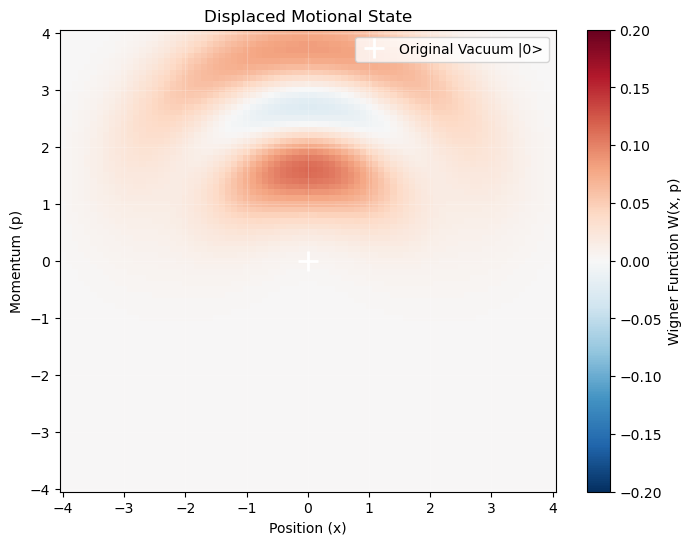

In [42]:
beta = SDF_apply_with_alpha_dephasing(1e3, 0, 2.0, false, nothing, 1, 365.0)
plot_wigner(beta)

Gamma_t = 0.16108723765003177, t_sig_s = 0.004413348976713199 s, eta = 0.04971125874691094, Omega_eff = 18232.111218474965 rad/s

Running master_dynamic (Drifting to macroscopic β=2.0 in the bath)...
Running Stepwise Analytical Open Theory (Trotter Expansion)...
Sweeping α (Evaluating Simulation, Exact Open Theory, and Closed Theory)...


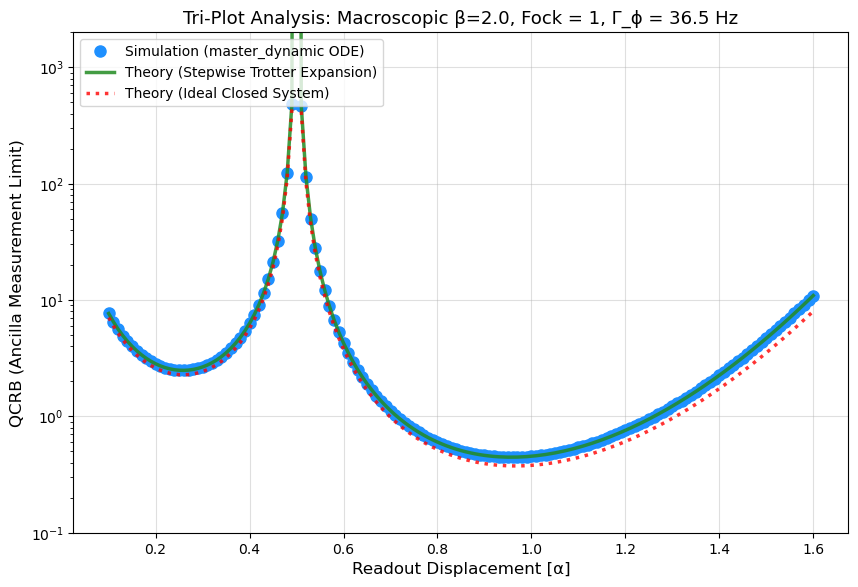

sys:1: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.


In [36]:
plot_qcrb_macroscopic_beta_comparative(1, 1e3, 36.5, 2.0)

Gamma_t = 3.9720140790418794, t_sig_s = 0.004413348976713199 s, eta = 0.04971125874691094, Omega_eff = 18232.111218474965 rad/s

Running master_dynamic (Drifting to macroscopic β=2.0 in the bath)...
Running Stepwise Analytical Open Theory (Trotter Expansion)...
Sweeping α (Evaluating Simulation, Exact Open Theory, and Closed Theory)...


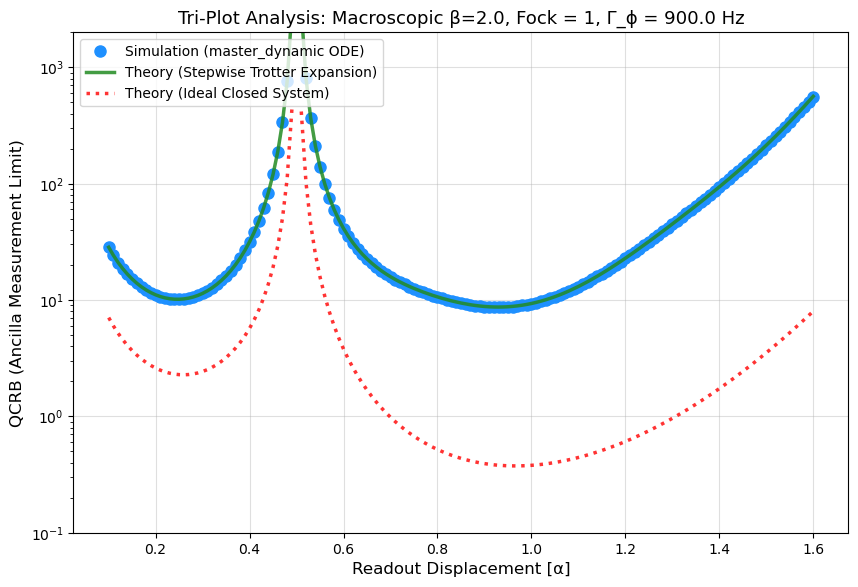

In [38]:
plot_qcrb_macroscopic_beta_comparative(1, 1e3, 900.0, 2.0)

Gamma_t = 0.8848764698309964, t_sig_s = 0.004413348976713199 s, eta = 0.04971125874691094, Omega_eff = 18232.111218474965 rad/s

Running master_dynamic (Drifting to macroscopic β=2.0 in the bath)...
Running Stepwise Analytical Open Theory (Trotter Expansion)...
Sweeping α (Evaluating Simulation, Exact Open Theory, and Closed Theory)...


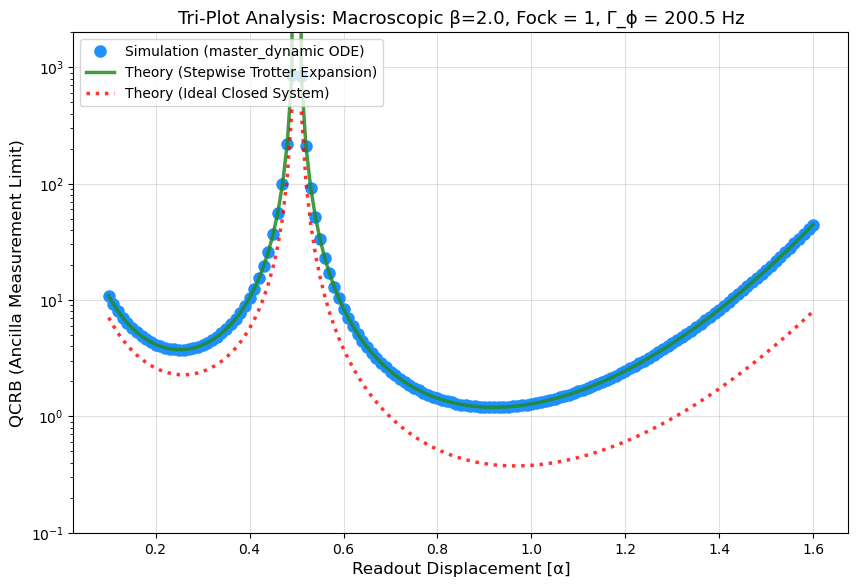

In [39]:
plot_qcrb_macroscopic_beta_comparative(1, 1e3, 200.5, 2.0)

Gamma_t = 0.8848764698309964, t_sig_s = 0.004413348976713199 s, eta = 0.04971125874691094, Omega_eff = 18232.111218474965 rad/s

Running master_dynamic (Drifting to macroscopic β=2.0 in the bath)...
Running Stepwise Analytical Open Theory (Trotter Expansion)...
Sweeping α (Evaluating Simulation, Exact Open Theory, and Closed Theory)...


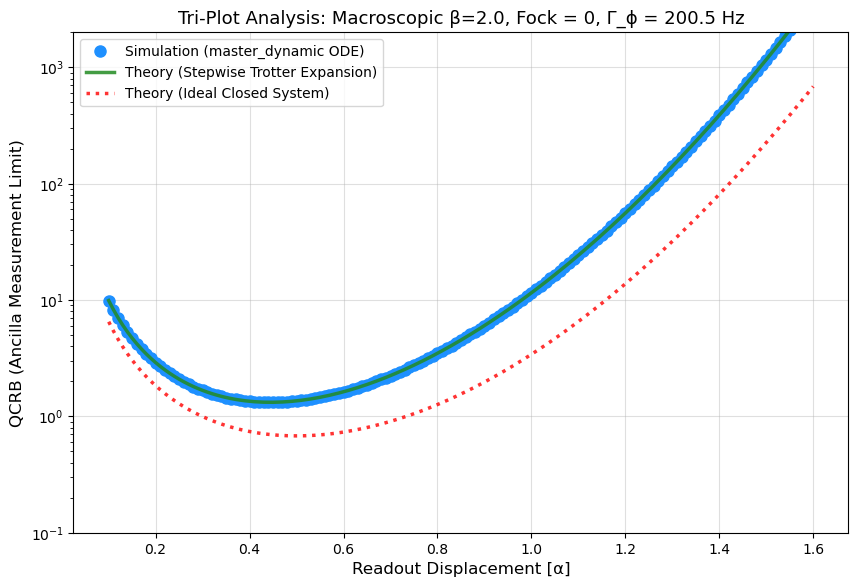

In [40]:
plot_qcrb_macroscopic_beta_comparative(0, 1e3, 200.5, 2.0)

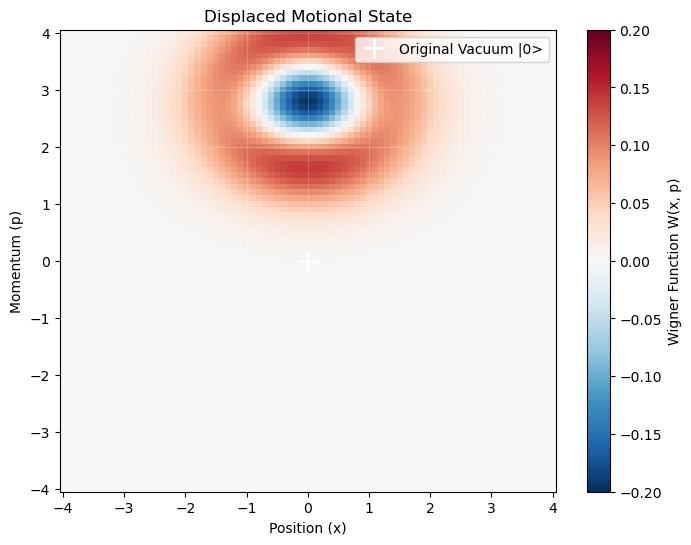

In [46]:
beta = SDF_apply_with_alpha_dephasing(1e3, 0, 2.0, false, nothing, 1, 32.6)
plot_wigner(beta)

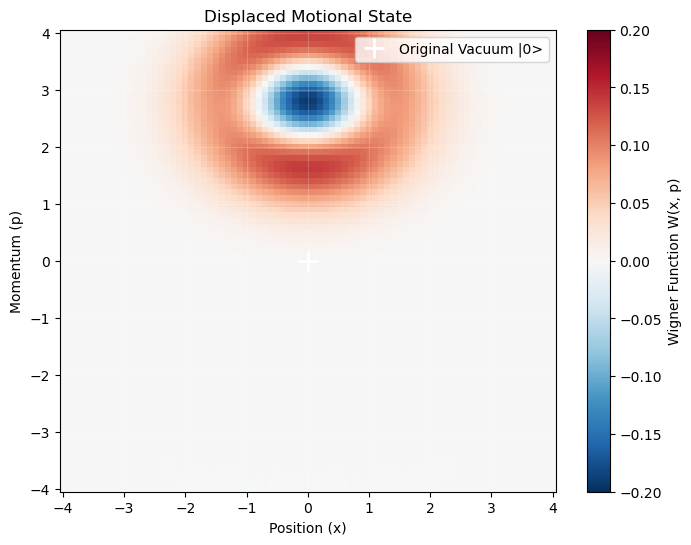

In [44]:
plot_wigner(beta)

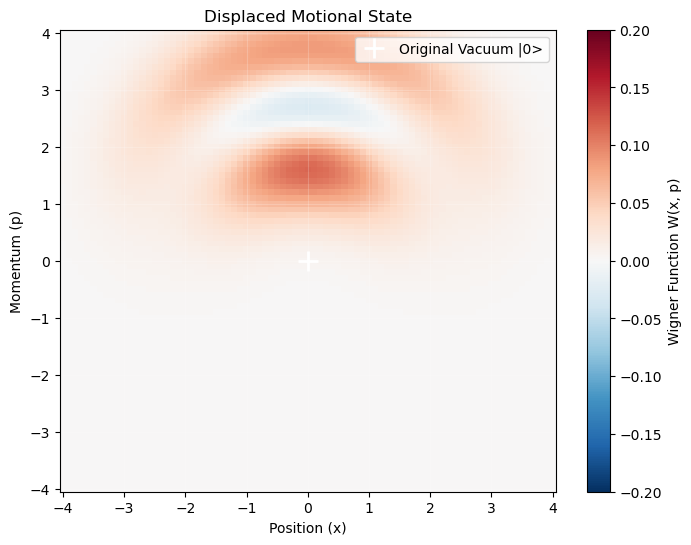

In [45]:
beta = SDF_apply_with_alpha_dephasing(1e3, 0, 2.0, false, nothing, 1, 340.0)
plot_wigner(beta)

Gamma_t = 0.13460714378975258, t_sig_s = 0.004413348976713199 s, eta = 0.04971125874691094, Omega_eff = 18232.111218474965 rad/s

Running master_dynamic (Drifting to macroscopic β=2.0 in the bath)...
Running Stepwise Analytical Open Theory (Trotter Expansion)...
Sweeping α (Evaluating Simulation, Exact Open Theory, and Closed Theory)...


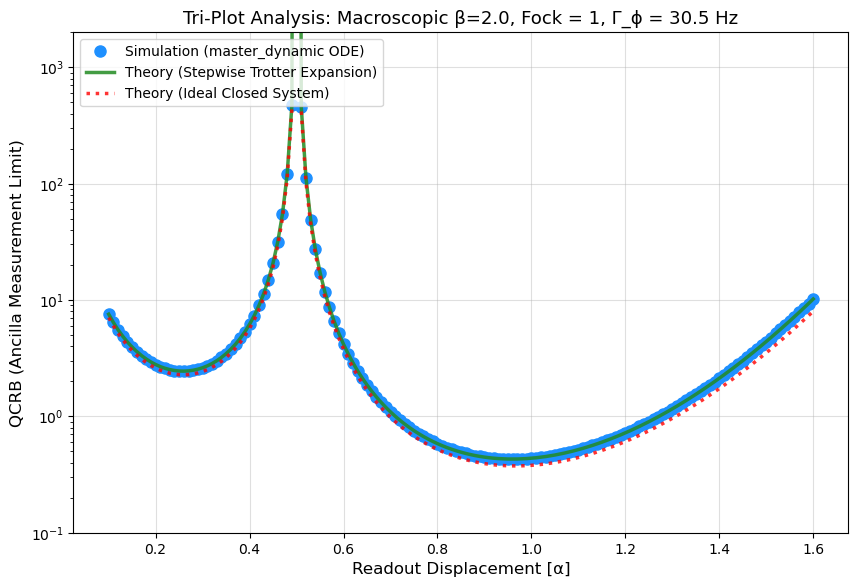

In [50]:
plot_qcrb_macroscopic_beta_comparative(1, 1e3, 30.5, 2.0)

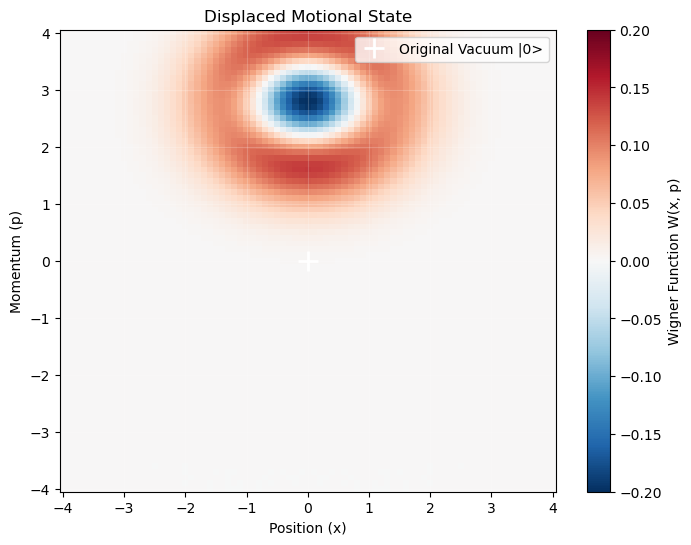

In [51]:
beta = SDF_apply_with_alpha_dephasing(1e3, 0, 2.0, false, nothing, 1, 30.5)
plot_wigner(beta)